# Etap 5 — Metody uczenia maszynowego i ich zastosowanie w analizie danych

**Cel:** poznanie podstawowych metod uczenia maszynowego, różnic między algorytmami nadzorowanymi i nienadzorowanymi oraz ich łączenia.
**Rezultat etapu:** opracowany model uczenia maszynowego (drzewo decyzyjne, scikit-learn) i jego zastosowanie w analizie dostępności mieszkań.

## 5.1 Podstawy uczenia maszynowego

**Uczenie maszynowe (ML)** to dziedzina sztucznej inteligencji, w której algorytm *uczy się zależności z danych* zamiast wykonywać ręcznie zapisane reguły.
Model dopasowuje parametry na **zbiorze uczącym**, a jego jakość sprawdzamy na **zbiorze testowym** — danych, których wcześniej „nie widział”.

### Metody nadzorowane i nienadzorowane

| | **Uczenie nadzorowane** | **Uczenie nienadzorowane** |
|---|---|---|
| Dane | atrybuty **i znana odpowiedź** (etykieta / wartość) | tylko atrybuty, **brak odpowiedzi** |
| Cel | nauczyć się przewidywać odpowiedź dla nowych obiektów | odkryć strukturę: grupy, wzorce, wymiary |
| Zadania | **klasyfikacja**, **regresja** | grupowanie (K-means, hierarchiczne), redukcja wymiarowości (PCA) |
| Ocena | porównanie z prawdą: MAE, R², accuracy, F1 | miary wewnętrzne: silhouette, inercja |
| Przykład w projekcie | wycena mieszkania, segment cenowy oferty | segmentacja rynku ofert, grupy miast (etap 6) |

### Predykcja, klasyfikacja, regresja

- **Predykcja** — ogólne pojęcie: przewidywanie nieznanej wartości na podstawie znanych cech (obejmuje klasyfikację i regresję; także prognozy w czasie).
- **Klasyfikacja** — przewidywana wartość jest **kategorią** (skończony zbiór klas), np. *tanie / średnie / drogie*.
- **Regresja** — przewidywana wartość jest **liczbą ciągłą**, np. cena za m² w PLN.

| Pytanie w naszych danych | Typ zmiennej celu | Kategoria zadania |
|---|---|---|
| Ile kosztuje m² tego mieszkania? | liczba (PLN/m²) | **regresja** (nadzorowane) |
| Czy oferta jest tania, średnia czy droga jak na swoje miasto? | kategoria (3 klasy) | **klasyfikacja** (nadzorowane) |
| Ile będzie kosztować m² w kolejnym miesiącu? | liczba w czasie | **predykcja / prognoza** szeregu czasowego |
| Jakie naturalne segmenty ofert istnieją na rynku? | brak zmiennej celu | **grupowanie** (nienadzorowane) |

### Przykłady zastosowań w różnych dziedzinach

| Dziedzina | Klasyfikacja | Regresja / predykcja | Grupowanie |
|---|---|---|---|
| **Medycyna** | diagnoza: chory / zdrowy na podstawie badań | przewidywanie długości hospitalizacji | grupy pacjentów o podobnym przebiegu choroby |
| **Marketing** | czy klient zrezygnuje z usługi (*churn*) | przewidywana wartość klienta (CLV) | segmentacja klientów |
| **Finanse** | ocena ryzyka kredytowego (spłaci / nie spłaci) | prognoza ceny akcji, wycena nieruchomości | wykrywanie nietypowych transakcji |

### Porównanie metod — zastosowania i ograniczenia

- **Nadzorowane:** dają konkretne, mierzalne odpowiedzi, ale wymagają etykiet (często kosztownych) i nauczą się tylko tego, co jest w danych (np. błędów i uprzedzeń w etykietach). Ryzyko **przeuczenia**.
- **Nienadzorowane:** nie wymagają etykiet i odkrywają nieznane wzorce, ale wyniki trudniej ocenić obiektywnie, a interpretacja grup zależy od analityka (np. wybór liczby klastrów).

### Łączenie metod
Metody można łączyć, np.: **PCA → model** (mniej atrybutów, brak współliniowości), **grupowanie → etykieta klastra jako nowy atrybut** modelu nadzorowanego,
albo **osobny model w każdym klastrze**. Łączenie metod realizujemy w etapie 6 (numer klastra jako atrybut drzewa decyzyjnego).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent))
from src.utils import *  # ścieżki, wczytywanie danych, styl wykresów

set_plot_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score,
                             mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, r2_score)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, export_text, plot_tree

## 5.2 Modelowanie — cel i przygotowanie danych wejściowych

**Cel modelowania:**
1. **Regresja** — przewidywanie ceny za m² oferty (automatyczna wycena mieszkania),
2. **Klasyfikacja** — przypisanie oferty do segmentu cenowego w swoim mieście (*tanie / średnie / drogie*) — np. do wykrywania okazji.

**Algorytm:** drzewo decyzyjne — model nieliniowy, nie wymaga normalizacji, dobrze radzi sobie z atrybutami różnych typów i jest **interpretowalny** (zbiór reguł „jeżeli… to…”).

**Dane wejściowe** łączą **oba źródła**: cechy oferty (zbiór 1) + cechy miasta ze zbioru 2 (mediana pensji netto, indeks kosztów życia, liczba ludności).
Atrybuty kategoryczne kodujemy metodą *one-hot*. Nie używamy atrybutów, które wprost zawierają cenę (wyciek informacji).

In [2]:
sales = pd.read_csv(PROCESSED_DIR / "oferty_sprzedaz_clean.csv")
cities = pd.read_csv(PROCESSED_DIR / "miasta_wskazniki.csv")

city_features = cities.set_index("city_key")[["median_salary_net_pln", "cost_of_living_index", "population_approx"]]
data = sales.join(city_features, on="city")

NUMERIC = ["squareMeters", "rooms", "floor", "floorCount", "buildYear", "centreDistance", "poiCount",
           "schoolDistance", "clinicDistance", "postOfficeDistance", "kindergartenDistance", "restaurantDistance",
           "collegeDistance", "pharmacyDistance", "hasParkingSpace", "hasBalcony", "hasElevator", "hasSecurity",
           "hasStorageRoom", "median_salary_net_pln", "cost_of_living_index", "population_approx"]
CATEGORICAL = ["type", "ownership", "buildingMaterial", "condition"]

X = pd.get_dummies(data[NUMERIC + CATEGORICAL], columns=CATEGORICAL, dtype=int)
y_reg = data["price_per_m2"]
y_clf = data["segment_cenowy"]

X_train, X_test, yr_train, yr_test, yc_train, yc_test = train_test_split(
    X, y_reg, y_clf, test_size=0.2, random_state=RANDOM_STATE, stratify=data["city"])
print(f"Atrybuty wejściowe: {X.shape[1]} | zbiór uczący: {len(X_train):,} | testowy: {len(X_test):,}")
X.head(3)

Atrybuty wejściowe: 34 | zbiór uczący: 73,033 | testowy: 18,259


,squareMeters,rooms,floor,floorCount,buildYear,centreDistance,poiCount,schoolDistance,clinicDistance,postOfficeDistance,kindergartenDistance,restaurantDistance,collegeDistance,pharmacyDistance,hasParkingSpace,hasBalcony,hasElevator,hasSecurity,hasStorageRoom,median_salary_net_pln,cost_of_living_index,population_approx,type_apartmentBuilding,type_blockOfFlats,type_brak_danych,type_tenement,ownership_condominium,ownership_cooperative,buildingMaterial_brak_danych,buildingMaterial_brick,buildingMaterial_concreteSlab,condition_brak_danych,condition_low,condition_premium
0,63.00,3.00,4.00,10.00,"1,980.00",6.53,9.00,0.12,1.39,0.63,0.10,1.65,1.13,0.41,1,1,1,0,1,4584,78.00,400000,0,1,0,0,1,0,0,0,1,1,0,0
1,94.30,4.00,3.00,3.00,"1,950.00",8.95,12.00,0.23,3.11,0.29,0.09,0.35,1.18,0.19,0,0,0,0,1,5893,98.50,1800000,0,1,0,0,1,0,0,1,0,0,1,0
2,45.80,2.00,6.00,10.00,"1,975.00",6.66,15.00,0.22,0.59,0.25,0.18,0.25,2.69,0.23,0,0,1,0,1,5893,98.50,1800000,0,1,0,0,0,1,1,0,0,1,0,0


## 5.3 Regresja — drzewo decyzyjne przewidujące cenę za m²

Dobór hiperparametrów (`max_depth` — głębokość drzewa, `min_samples_leaf` — min. liczba ofert w liściu) wykonujemy
**walidacją krzyżową (5-fold)** na zbiorze uczącym. Zbiór testowy służy tylko do końcowej oceny.

In [3]:
grid_reg = GridSearchCV(
    DecisionTreeRegressor(random_state=RANDOM_STATE),
    param_grid={"max_depth": [4, 6, 8, 10, 12, 15, 20], "min_samples_leaf": [5, 20, 50]},
    cv=5, scoring="neg_mean_absolute_error", n_jobs=-1)
grid_reg.fit(X_train, yr_train)
tree_reg = grid_reg.best_estimator_
print("Najlepsze parametry:", grid_reg.best_params_, f"| MAE (CV): {-grid_reg.best_score_:,.0f} PLN/m²")

Najlepsze parametry: {'max_depth': 15, 'min_samples_leaf': 5} | MAE (CV): 1,591 PLN/m²


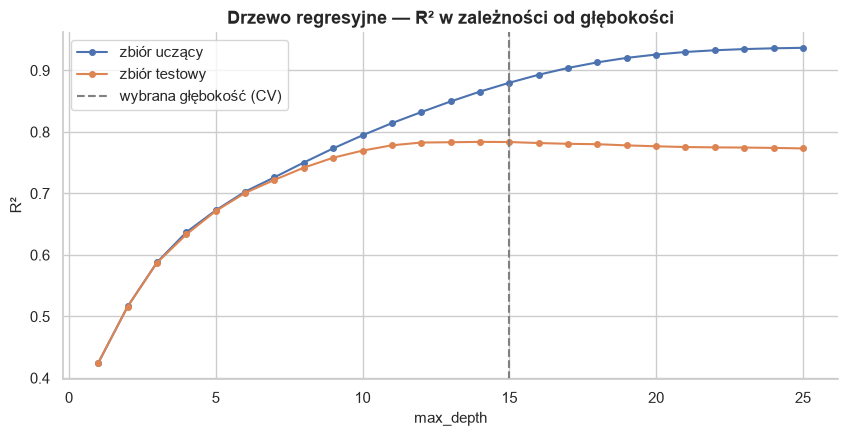

In [4]:
# wpływ głębokości drzewa — niedouczenie vs przeuczenie
depths = range(1, 26)
train_r2, test_r2 = [], []
for d in depths:
    m = DecisionTreeRegressor(max_depth=d, min_samples_leaf=grid_reg.best_params_["min_samples_leaf"],
                              random_state=RANDOM_STATE).fit(X_train, yr_train)
    train_r2.append(m.score(X_train, yr_train))
    test_r2.append(m.score(X_test, yr_test))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(depths, train_r2, marker="o", ms=4, label="zbiór uczący")
ax.plot(depths, test_r2, marker="o", ms=4, label="zbiór testowy")
ax.axvline(grid_reg.best_params_["max_depth"], color="gray", ls="--", label="wybrana głębokość (CV)")
ax.set_title("Drzewo regresyjne — R² w zależności od głębokości")
ax.set_xlabel("max_depth")
ax.set_ylabel("R²")
ax.legend()
save_fig(fig, "05_glebokosc_drzewa")
plt.show()

In [5]:
def reg_metrics(name, y_true, y_pred):
    return {"model": name, "MAE [PLN/m²]": mean_absolute_error(y_true, y_pred),
            "RMSE [PLN/m²]": mean_squared_error(y_true, y_pred) ** 0.5,
            "MAPE [%]": mean_absolute_percentage_error(y_true, y_pred) * 100, "R²": r2_score(y_true, y_pred)}

baseline = DummyRegressor(strategy="median").fit(X_train, yr_train)
linear = LinearRegression().fit(X_train, yr_train)
forest = RandomForestRegressor(n_estimators=150, max_depth=20, min_samples_leaf=3, n_jobs=-1,
                               random_state=RANDOM_STATE).fit(X_train, yr_train)
reg_results = pd.DataFrame([
    reg_metrics("bazowy (mediana)", yr_test, baseline.predict(X_test)),
    reg_metrics("regresja liniowa", yr_test, linear.predict(X_test)),
    reg_metrics(f"drzewo decyzyjne (głęb. {tree_reg.get_depth()})", yr_test, tree_reg.predict(X_test)),
    reg_metrics("las losowy (porównawczo)", yr_test, forest.predict(X_test)),
]).set_index("model")
reg_results

,MAE [PLN/m²],RMSE [PLN/m²],MAPE [%],R²
model,,,,
bazowy (mediana),"3,786.63","4,687.79",32.26,-0.01
regresja liniowa,"2,125.07","2,750.13",16.93,0.65
drzewo decyzyjne (głęb. 15),"1,553.16","2,173.40",11.78,0.78
las losowy (porównawczo),"1,244.09","1,762.09",9.51,0.86


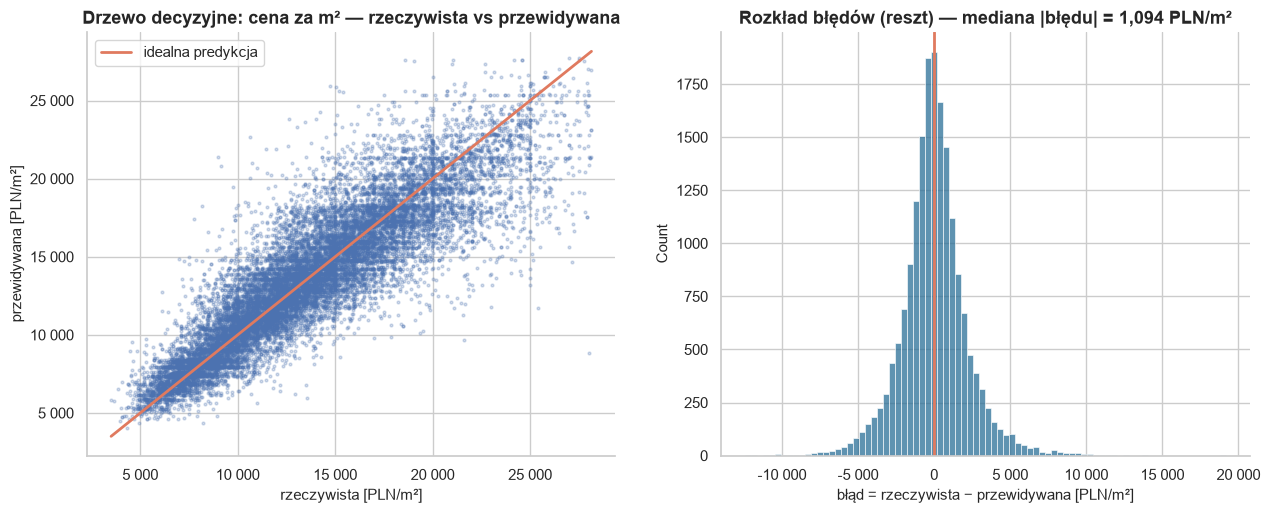

In [6]:
pred = tree_reg.predict(X_test)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].scatter(yr_test, pred, s=4, alpha=0.25)
lims = [yr_test.min(), yr_test.max()]
axes[0].plot(lims, lims, color="#e07a5f", lw=2, label="idealna predykcja")
axes[0].set_title("Drzewo decyzyjne: cena za m² — rzeczywista vs przewidywana")
axes[0].set_xlabel("rzeczywista [PLN/m²]")
axes[0].set_ylabel("przewidywana [PLN/m²]")
axes[0].legend()
resid = yr_test - pred
sns.histplot(resid, bins=80, ax=axes[1], color="#2a6f97")
axes[1].axvline(0, color="#e07a5f", lw=2)
axes[1].set_title(f"Rozkład błędów (reszt) — mediana |błędu| = {resid.abs().median():,.0f} PLN/m²")
axes[1].set_xlabel("błąd = rzeczywista − przewidywana [PLN/m²]")
for ax in axes:
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(thousands))
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(thousands))
save_fig(fig, "05_regresja_wyniki")
plt.show()

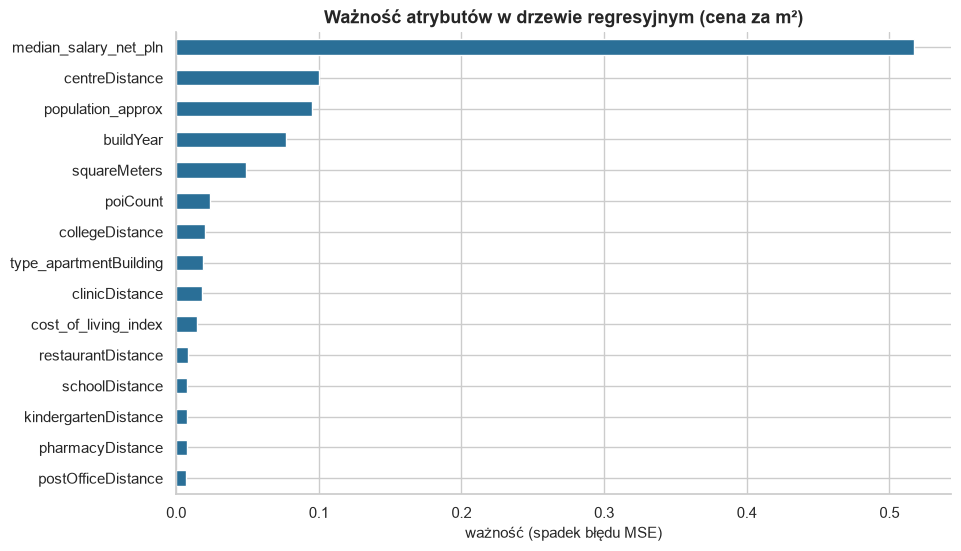

,ważność
median_salary_net_pln,0.52
centreDistance,0.10
population_approx,0.10
buildYear,0.08
squareMeters,0.05
poiCount,0.02
collegeDistance,0.02
type_apartmentBuilding,0.02
clinicDistance,0.02
cost_of_living_index,0.01


In [7]:
importance = pd.Series(tree_reg.feature_importances_, index=X.columns).sort_values(ascending=False)
top = importance.head(15)
fig, ax = plt.subplots(figsize=(10, 6))
top.sort_values().plot(kind="barh", ax=ax, color="#2a6f97")
ax.set_title("Ważność atrybutów w drzewie regresyjnym (cena za m²)")
ax.set_xlabel("ważność (spadek błędu MSE)")
save_fig(fig, "05_waznosc_atrybutow_regresja")
plt.show()
importance.head(10).round(3).to_frame("ważność")

### Wizualizacja reguł drzewa
Pełne drzewo jest zbyt duże do pokazania, dlatego rysujemy **drzewo o głębokości 3** wytrenowane na tych samych danych — pokazuje najważniejsze reguły podziału.

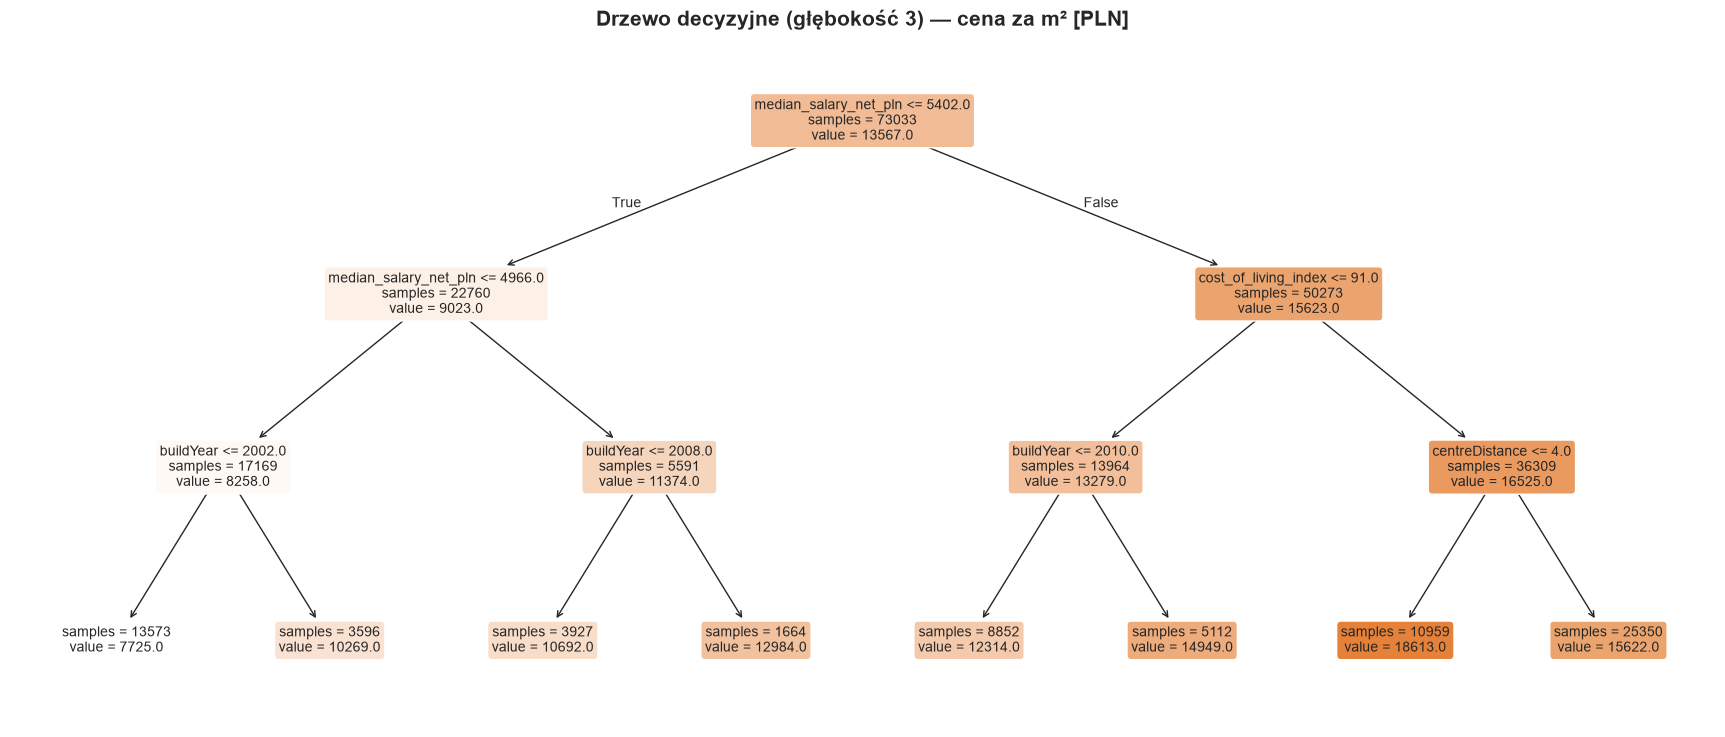

|--- median_salary_net_pln <= 5402
|   |--- median_salary_net_pln <= 4966
|   |   |--- buildYear <= 2002
|   |   |   |--- value: [7725]
|   |   |--- buildYear >  2002
|   |   |   |--- value: [10269]
|   |--- median_salary_net_pln >  4966
|   |   |--- buildYear <= 2008
|   |   |   |--- value: [10692]
|   |   |--- buildYear >  2008
|   |   |   |--- value: [12984]
|--- median_salary_net_pln >  5402
|   |--- cost_of_living_index <= 91
|   |   |--- buildYear <= 2010
|   |   |   |--- value: [12314]
|   |   |--- buildYear >  2010
|   |   |   |--- value: [14949]
|   |--- cost_of_living_index >  91
|   |   |--- centreDistance <= 4
|   |   |   |--- value: [18613]
|   |   |--- centreDistance >  4
|   |   |   |--- value: [15622]



In [8]:
small_tree = DecisionTreeRegressor(max_depth=3, random_state=RANDOM_STATE).fit(X_train, yr_train)
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(small_tree, feature_names=X.columns, filled=True, rounded=True, fontsize=10, impurity=False,
          precision=0, ax=ax)
ax.set_title("Drzewo decyzyjne (głębokość 3) — cena za m² [PLN]", fontsize=15, fontweight="bold")
save_fig(fig, "05_drzewo_regresja")
plt.show()
print(export_text(small_tree, feature_names=list(X.columns), decimals=0))

## 5.4 Klasyfikacja — segment cenowy oferty w mieście

Klasy są zrównoważone (tercyle → po ~33%), więc model losowy osiąga ok. 33% trafności. Miary: **accuracy**, **F1 (makro)**, macierz pomyłek.

In [9]:
grid_clf = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid={"max_depth": [4, 6, 8, 10, 12, 15], "min_samples_leaf": [5, 20, 50], "criterion": ["gini", "entropy"]},
    cv=5, scoring="f1_macro", n_jobs=-1)
grid_clf.fit(X_train, yc_train)
tree_clf = grid_clf.best_estimator_
print("Najlepsze parametry:", grid_clf.best_params_, f"| F1 makro (CV): {grid_clf.best_score_:.3f}")

dummy_clf = DummyClassifier(strategy="most_frequent").fit(X_train, yc_train)
yc_pred = tree_clf.predict(X_test)
clf_results = pd.DataFrame([
    {"model": "bazowy (najczęstsza klasa)", "accuracy": accuracy_score(yc_test, dummy_clf.predict(X_test)),
     "F1 makro": f1_score(yc_test, dummy_clf.predict(X_test), average="macro")},
    {"model": f"drzewo decyzyjne (głęb. {tree_clf.get_depth()})", "accuracy": accuracy_score(yc_test, yc_pred),
     "F1 makro": f1_score(yc_test, yc_pred, average="macro")},
]).set_index("model")
clf_results

Najlepsze parametry: {'criterion': 'entropy', 'max_depth': 15, 'min_samples_leaf': 5} | F1 makro (CV): 0.621


,accuracy,F1 makro
model,,
bazowy (najczęstsza klasa),0.33,0.17
drzewo decyzyjne (głęb. 15),0.62,0.62


              precision    recall  f1-score   support

       tanie      0.652     0.671     0.661      6053
     średnie      0.518     0.530     0.524      6138
      drogie      0.707     0.670     0.688      6068

    accuracy                          0.623     18259
   macro avg      0.626     0.624     0.625     18259
weighted avg      0.625     0.623     0.624     18259



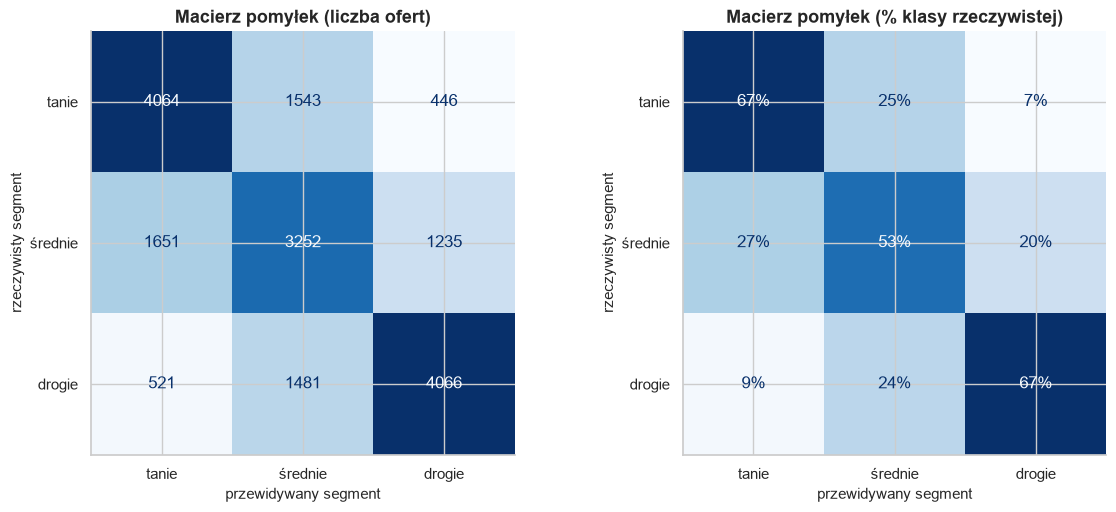

In [10]:
labels = ["tanie", "średnie", "drogie"]
print(classification_report(yc_test, yc_pred, labels=labels, digits=3))
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
ConfusionMatrixDisplay.from_predictions(yc_test, yc_pred, labels=labels, cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Macierz pomyłek (liczba ofert)")
ConfusionMatrixDisplay.from_predictions(yc_test, yc_pred, labels=labels, cmap="Blues", ax=axes[1],
                                        normalize="true", values_format=".0%", colorbar=False)
axes[1].set_title("Macierz pomyłek (% klasy rzeczywistej)")
for ax in axes:
    ax.set_xlabel("przewidywany segment")
    ax.set_ylabel("rzeczywisty segment")
save_fig(fig, "05_klasyfikacja_macierz_pomylek")
plt.show()

In [11]:
imp_clf = pd.Series(tree_clf.feature_importances_, index=X.columns).sort_values(ascending=False)
pd.DataFrame({"ważność — regresja": importance, "ważność — klasyfikacja": imp_clf}) \
  .sort_values("ważność — klasyfikacja", ascending=False).head(12).round(3)

,ważność — regresja,ważność — klasyfikacja
squareMeters,0.05,0.16
buildYear,0.08,0.15
centreDistance,0.10,0.14
poiCount,0.02,0.07
collegeDistance,0.02,0.06
clinicDistance,0.02,0.05
restaurantDistance,0.01,0.04
pharmacyDistance,0.01,0.04
median_salary_net_pln,0.52,0.04
postOfficeDistance,0.01,0.03


## 5.5 Zastosowanie praktyczne — wycena typowego mieszkania w każdym mieście

Używamy wytrenowanego drzewa jako **kalkulatora wyceny**: typowe mieszkanie 50 m², 2 pokoje, 3. piętro w 5-piętrowym bloku z windą,
rok budowy 2015, 3 km od centrum (pozostałe cechy — mediany). Wynik zestawiamy z pensją netto w mieście (pytanie 1).

In [12]:
template = X_train.median(numeric_only=True).to_frame().T
template[[c for c in X.columns if c.startswith(("type_", "ownership_", "buildingMaterial_", "condition_"))]] = 0
template[["type_blockOfFlats", "ownership_condominium", "buildingMaterial_brick", "condition_brak_danych"]] = 1
template[["squareMeters", "rooms", "floor", "floorCount", "buildYear", "centreDistance", "hasElevator"]] = [50, 2, 3, 5, 2015, 3, 1]

rows = []
for _, c in cities.iterrows():
    x = template.copy()
    x[["median_salary_net_pln", "cost_of_living_index", "population_approx"]] = \
        [c["median_salary_net_pln"], c["cost_of_living_index"], c["population_approx"]]
    ppm = forest.predict(x[X.columns])[0], tree_reg.predict(x[X.columns])[0]
    rows.append({"miasto": c["miasto"], "cena m² — drzewo": ppm[1], "cena m² — las losowy": ppm[0],
                 "wartość 50 m² (drzewo)": ppm[1] * 50, "pensja netto": c["median_salary_net_pln"],
                 "liczba pensji (drzewo)": ppm[1] * 50 / c["median_salary_net_pln"]})
valuation = pd.DataFrame(rows).sort_values("liczba pensji (drzewo)", ascending=False).set_index("miasto")
valuation.round(0)

,cena m² — drzewo,cena m² — las losowy,wartość 50 m² (drzewo),pensja netto,liczba pensji (drzewo)
miasto,,,,,
Warszawa,"20,996.00","20,423.00","1,049,824.00",5893,178.00
Gdańsk,"19,319.00","19,588.00","965,943.00",5457,177.00
Kraków,"16,975.00","17,604.00","848,738.00",5566,152.00
Wrocław,"17,064.00","15,646.00","853,189.00",5675,150.00
Gdynia,"15,064.00","14,442.00","753,199.00",5239,144.00
Łódź,"11,636.00","10,610.00","581,781.00",4420,132.00
Bydgoszcz,"11,636.00","10,419.00","581,781.00",4475,130.00
Szczecin,"11,602.00","11,626.00","580,108.00",4584,127.00
Poznań,"13,268.00","12,687.00","663,411.00",5348,124.00


## 5.6 Zapis wyników

In [13]:
model_results = pd.concat([
    reg_results.reset_index().assign(zadanie="regresja: cena za m²"),
    clf_results.reset_index().assign(zadanie="klasyfikacja: segment cenowy"),
], ignore_index=True)
model_results.to_csv(PROCESSED_DIR / "wyniki_modeli.csv", index=False)

test_out = data.loc[X_test.index, ["id", "city", "city_label", "squareMeters", "buildYear", "centreDistance",
                                   "price", "price_per_m2", "segment_cenowy"]].copy()
test_out["pred_price_per_m2"] = tree_reg.predict(X_test).round(0)
test_out["pred_segment"] = yc_pred
test_out["blad_price_per_m2"] = test_out["price_per_m2"] - test_out["pred_price_per_m2"]
test_out.to_csv(PROCESSED_DIR / "predykcje_test.csv", index=False)

importance.rename("waznosc").rename_axis("atrybut").reset_index().to_csv(PROCESSED_DIR / "waznosc_atrybutow.csv", index=False)
valuation.reset_index().to_csv(PROCESSED_DIR / "wycena_typowego_mieszkania.csv", index=False)
model_results

,model,MAE [PLN/m²],RMSE [PLN/m²],MAPE [%],R²,zadanie,accuracy,F1 makro
0,bazowy (mediana),"3,786.63","4,687.79",32.26,-0.01,regresja: cena za m²,NaN,NaN
1,regresja liniowa,"2,125.07","2,750.13",16.93,0.65,regresja: cena za m²,NaN,NaN
2,drzewo decyzyjne (głęb. 15),"1,553.16","2,173.40",11.78,0.78,regresja: cena za m²,NaN,NaN
3,las losowy (porównawczo),"1,244.09","1,762.09",9.51,0.86,regresja: cena za m²,NaN,NaN
4,bazowy (najczęstsza klasa),NaN,NaN,NaN,NaN,klasyfikacja: segment cenowy,0.33,0.17
5,drzewo decyzyjne (głęb. 15),NaN,NaN,NaN,NaN,klasyfikacja: segment cenowy,0.62,0.62


## 5.7 Wyniki i możliwości praktycznego wykorzystania

**Regresja (cena za m²):**
- Drzewo decyzyjne (głębokość 15, dobrana walidacją krzyżową) osiąga na zbiorze testowym **R² = 0,78**, MAE ≈ **1 550 PLN/m²** (MAPE ≈ 12%) —
  znacznie lepiej niż model bazowy (MAE ≈ 3 790) i regresja liniowa (R² = 0,65), co potwierdza **nieliniowy** charakter zależności (por. etap 4).
- Las losowy (zespół wielu drzew) jest jeszcze dokładniejszy (R² = 0,86), ale traci interpretowalność pojedynczego drzewa.
- Wykres głębokości pokazuje typowy kompromis: płytkie drzewa są **niedouczone**, bardzo głębokie zaczynają się **przeuczać** — od głębokości ~12 R² na zbiorze uczącym rośnie dalej (do ~0,94), a na testowym stoi w miejscu (~0,78) i lekko spada.
- Najważniejsze atrybuty: **poziom płac w mieście** (zbiór 2 — w praktyce reprezentuje rynek lokalny), **odległość od centrum**, **wielkość miasta**, **rok budowy**, **metraż**.
  Pierwsze podziały drzewa to: *bogate miasto? → nowy budynek? → blisko centrum?* — czytelne reguły wyceny.
- Ograniczenie: miasta o identycznej medianie płac (np. Lublin i Rzeszów, Częstochowa i Radom) model rozróżnia tylko pośrednio (liczba ludności) — dokładniejszy byłby atrybut miasta lub współrzędne.

**Klasyfikacja (segment cenowy w mieście):**
- Trafność **62%** przy 33% dla modelu bazowego (3 zrównoważone klasy). Najlepiej rozpoznawane są segmenty skrajne (*tanie* i *drogie*, F1 ≈ 0,66–0,69);
  segment *średni* jest najtrudniejszy (F1 ≈ 0,52) — myli się z sąsiednimi, co jest naturalne dla granic tercyli.
- Tu ważniejsze są cechy samego mieszkania (metraż, rok budowy, odległość od centrum, usługi w okolicy), bo segment liczony jest *względem miasta*.

**Praktyczne wykorzystanie:**
- **Wycena / wykrywanie okazji** — oferta wyraźnie tańsza od wyceny modelu (lub klasyfikowana jako „droga”, a wystawiona jak „tania”) to kandydat do sprawdzenia przez kupującego lub inwestora.
- **Kalkulator dostępności** — to samo mieszkanie (50 m², 2015 r., 3 km od centrum) kosztuje ok. **178 pensji netto w Warszawie i Gdańsku**, a ok. **111 w Częstochowie i Radomiu** (pytanie 1).
- **Analiza wrażliwości** — model pozwala sprawdzić, o ile spada cena przy oddaleniu od centrum lub wyborze starszego budynku (pytanie 3).